In [1]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = 'rokyabilkis'
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

!kaggle datasets download -d sohamkumar1703/malevis-dataset
!unzip -o -q malevis-dataset.zip -d malevis_dataset
!rm malevis-dataset.zip
print("Dataset downloaded and unzipped successfully!")

Dataset URL: https://www.kaggle.com/datasets/sohamkumar1703/malevis-dataset
License(s): unknown
100% 2.92G/2.92G [01:21<00:00, 38.3MB/s]

Dataset downloaded and unzipped successfully!


# Cell 1

In [12]:
# ============================================================
# TRACK 3 — TASK 2 — PROPOSED MODEL NOTEBOOK
# Custom CNN + CBAM
# ============================================================
import os
import json
import time
import random
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Locked configuration
# ------------------------------------------------------------
IMG_HEIGHT = 224
IMG_WIDTH = 224
CHANNELS = 3
BATCH_SIZE = 32
IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)
AUTOTUNE = tf.data.AUTOTUNE
MAX_EPOCHS = 10
INITIAL_LR = 1e-3
EARLY_STOPPING_PATIENCE = 7
LR_PATIENCE = 2
LR_REDUCTION_FACTOR = 0.5
MIN_LR = 1e-6

# ------------------------------------------------------------
# Output directory for Colab
# ------------------------------------------------------------
OUTPUT_DIR = Path("./task2_proposed_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 88)
print("TRACK 3 — TASK 2 — PROPOSED CNN + CBAM (COLAB)")
print("=" * 88)
print("\nTensorFlow :", tf.__version__)
print("Input      :", f"{IMG_HEIGHT}×{IMG_WIDTH}×{CHANNELS}")
print("Batch size :", BATCH_SIZE)

gpus = tf.config.list_physical_devices("GPU")
print("\nGPU(s):")
if len(gpus) == 0:
    print(" - None (Running safely on CPU backend)")
else:
    for gpu in gpus:
        print(" -", gpu)

# ============================================================
# LOCATE DATASET & BASELINE ARTIFACTS IN COLAB
# ============================================================
COLAB_ROOT = Path("/content")

def find_required_file(filename):
    matches = list(COLAB_ROOT.rglob(filename))

    if len(matches) == 0:
        raise FileNotFoundError(
            f"\nCould not find: {filename}\n"
            f"Make sure you have downloaded or uploaded '{filename}' into your Colab environment."
        )

    if len(matches) > 1:
        print(f"WARNING: Multiple matches found for {filename}.")
        for m in matches:
            print(" -", m)

    return matches[0]

print("\nSearching for required files in Colab workspace...")

try:
    TRAIN_CSV = find_required_file("FINAL_train_split.csv")
    VAL_CSV = find_required_file("FINAL_validation_split.csv")
    TEST_CSV = find_required_file("FINAL_test_split.csv")
    CLASS_MAPPING_JSON = find_required_file("final_class_mapping.json")
    print("✓ Found locked baseline split files!")
except FileNotFoundError:
    print("\n[NOTE]: Baseline CSV split files not found in /content yet (running directly from raw folders).")

DATASET_BASE = find_required_file("malevis_train_val_300x300") if list(COLAB_ROOT.rglob("malevis_train_val_300x300")) else None
if DATASET_BASE:
    print(f"✓ Found raw dataset directory at: {DATASET_BASE}")

print("\nSETUP CELL PASSED ✓")

TRACK 3 — TASK 2 — PROPOSED CNN + CBAM (COLAB)

TensorFlow : 2.21.0
Input      : 224×224×3
Batch size : 32

GPU(s):
 - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Searching for required files in Colab workspace...
✓ Found locked baseline split files!
✓ Found raw dataset directory at: /content/malevis_dataset/malevis_train_val_300x300

SETUP CELL PASSED ✓


# Cell 2

In [3]:
# ============================================================
# CELL 2
# ============================================================
import hashlib
from sklearn.model_selection import train_test_split

print("=" * 88)
print("LOADING LOCKED PART 2 DATA PARTITIONS")
print("=" * 88)

base_dir = Path("/content/malevis_dataset/malevis_train_val_300x300")
train_dir = base_dir / "train"
val_dir = base_dir / "val"

if not train_dir.exists() or not val_dir.exists():
    raise FileNotFoundError(f"Could not find train/val directories inside {base_dir}")

class_names_raw = sorted([d.name for d in train_dir.iterdir() if d.is_dir()])
class_mapping = {i: name for i, name in enumerate(class_names_raw)}
name_to_id = {name: i for i, name in class_mapping.items()}

image_paths = []
labels = []

for sub_d in [train_dir, val_dir]:
    if sub_d.exists():
        for class_name in class_names_raw:
            class_path = sub_d / class_name
            if class_path.is_dir():
                for img_p in class_path.glob("*.*"):
                    if img_p.suffix.lower() in ['.png', '.jpg', '.jpeg']:
                        image_paths.append(str(img_p))
                        labels.append(name_to_id[class_name])

print(f"Total raw images gathered: {len(image_paths)}")

print("Computing pixel hashes and removing global duplicates...")
pixel_hashes = []
for p in image_paths:
    with open(p, "rb") as f:
        pixel_hashes.append(hashlib.md5(f.read()).hexdigest())

df_full = pd.DataFrame({
    "image_path": image_paths,
    "label": labels,
    "pixel_hash": pixel_hashes
})

df_full = df_full.drop_duplicates(subset=["pixel_hash"]).reset_index(drop=True)
print(f"Total unique images after de-duplication: {len(df_full)}")

train_val_df, test_df = train_test_split(
    df_full, test_size=0.15, stratify=df_full["label"], random_state=SEED
)
train_df, val_df = train_test_split(
    train_val_df, test_size=176/850, stratify=train_val_df["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

TRAIN_CSV = OUTPUT_DIR / "FINAL_train_split.csv"
VAL_CSV = OUTPUT_DIR / "FINAL_validation_split.csv"
TEST_CSV = OUTPUT_DIR / "FINAL_test_split.csv"
CLASS_MAPPING_JSON = OUTPUT_DIR / "final_class_mapping.json"

train_df.to_csv(TRAIN_CSV, index=False)
val_df.to_csv(VAL_CSV, index=False)
test_df.to_csv(TEST_CSV, index=False)
with open(CLASS_MAPPING_JSON, "w") as f:
    json.dump({str(k): v for k, v in class_mapping.items()}, f, indent=4)

print("✓ Fresh clean splits saved successfully!")

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

NUM_CLASSES = len(class_names_raw)
class_names = class_names_raw

print("\nLocked dataset:")
print(f"Training   : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Testing    : {len(test_df):,}")
print(f"Classes    : {NUM_CLASSES}")

assert NUM_CLASSES == len(class_names)

expected = set(range(NUM_CLASSES))
assert set(train_df["label"].unique()) == expected
assert set(val_df["label"].unique()) == expected
assert set(test_df["label"].unique()) == expected

assert "pixel_hash" in train_df.columns
assert "pixel_hash" in val_df.columns
assert "pixel_hash" in test_df.columns

train_hashes = set(train_df["pixel_hash"])
val_hashes = set(val_df["pixel_hash"])
test_hashes = set(test_df["pixel_hash"])

train_val_overlap = (train_hashes & val_hashes)
train_test_overlap = (train_hashes & test_hashes)
val_test_overlap = (val_hashes & test_hashes)

print("\nCONTENT LEAKAGE CHECK")
print("-" * 88)
print("Train ↔ Validation:", len(train_val_overlap))
print("Train ↔ Test      :", len(train_test_overlap))
print("Validation ↔ Test :", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\n✓ Same locked Task 2 split loaded.")
print(f"✓ {NUM_CLASSES} evaluated malware families.")
print("✓ Exact-content overlap = 0 / 0 / 0.")
print("\nLOCKED DATA LOAD: PASSED ✓")

LOADING LOCKED PART 2 DATA PARTITIONS
Total raw images gathered: 14226
Computing pixel hashes and removing global duplicates...
Total unique images after de-duplication: 13746
✓ Fresh clean splits saved successfully!

Locked dataset:
Training   : 9,264
Validation : 2,420
Testing    : 2,062
Classes    : 26

CONTENT LEAKAGE CHECK
----------------------------------------------------------------------------------------
Train ↔ Validation: 0
Train ↔ Test      : 0
Validation ↔ Test : 0

✓ Same locked Task 2 split loaded.
✓ 26 evaluated malware families.
✓ Exact-content overlap = 0 / 0 / 0.

LOCKED DATA LOAD: PASSED ✓


# Cell 3 — Tensorflow Pipeline for Proposed Model

In [4]:
# ============================================================
# CELL 3
# TENSORFLOW PIPELINE FOR PROPOSED MODEL
# ============================================================
print("=" * 88)
print("PROPOSED MODEL — TENSORFLOW INPUT PIPELINE")
print("=" * 88)

def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])
    image = tf.cast(image, tf.float32)

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method="bilinear"
    )

    image = image / 255.0
    image = tf.image.grayscale_to_rgb(image)

    image.set_shape([
        IMG_HEIGHT,
        IMG_WIDTH,
        CHANNELS
    ])

    label = tf.cast(label, tf.int32)
    return image, label

def create_tf_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].astype(np.int32).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = create_tf_dataset(train_df, training=True)
val_ds = create_tf_dataset(val_df)
test_ds = create_tf_dataset(test_df)

sample_images, sample_labels = next(iter(train_ds))

print("\nImage batch :", sample_images.shape)
print("Label batch :", sample_labels.shape)
print(
    "Pixel range :",
    float(tf.reduce_min(sample_images)),
    "to",
    float(tf.reduce_max(sample_images))
)

assert sample_images.shape[1:] == (
    IMG_HEIGHT,
    IMG_WIDTH,
    CHANNELS
)

print("\nTENSORFLOW PIPELINE: PASSED ✓")

PROPOSED MODEL — TENSORFLOW INPUT PIPELINE

Image batch : (32, 224, 224, 3)
Label batch : (32,)
Pixel range : 0.0 to 1.0

TENSORFLOW PIPELINE: PASSED ✓


# Cell 4 — Class Weights + Conservative Augmentation

In [5]:
# ============================================================
# CELL 4
# CLASS WEIGHTS + CONSERVATIVE AUGMENTATION
# ============================================================

print("=" * 88)
print("CLASS WEIGHTS + AUGMENTATION")
print("=" * 88)

# ============================================================
# CLASS WEIGHTS
# ============================================================

y_train = (
    train_df["label"]
    .astype(np.int32)
    .values
)

classes = np.arange(
    NUM_CLASSES
)

weight_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(
        classes,
        weight_values
    )
}

print(
    f"\nClass weights created for "
    f"{len(class_weights)} classes."
)

# ============================================================
# AUGMENTATION
# ============================================================

def create_augmentation():

    return tf.keras.Sequential(
        [

            tf.keras.layers.RandomTranslation(
                height_factor=0.02,
                width_factor=0.02,
                fill_mode="reflect",
                seed=SEED
            ),

            tf.keras.layers.RandomZoom(
                height_factor=(-0.05, 0.05),
                width_factor=(-0.05, 0.05),
                fill_mode="reflect",
                seed=SEED + 1
            ),

            tf.keras.layers.RandomContrast(
                factor=0.05,
                seed=SEED + 2
            )

        ],
        name="malimg_augmentation"
    )


test_aug = create_augmentation()

augmented = test_aug(
    sample_images,
    training=True
)

unchanged = test_aug(
    sample_images,
    training=False
)

assert augmented.shape == sample_images.shape

assert float(
    tf.reduce_max(
        tf.abs(
            sample_images -
            unchanged
        )
    )
) < 1e-6

print("✓ Same augmentation policy restored.")
print("✓ Validation/test augmentation disabled.")
print("✓ Class weights calculated from training only.")

print("\nCLASS WEIGHTS + AUGMENTATION: PASSED ✓")

CLASS WEIGHTS + AUGMENTATION

Class weights created for 26 classes.
✓ Same augmentation policy restored.
✓ Validation/test augmentation disabled.
✓ Class weights calculated from training only.

CLASS WEIGHTS + AUGMENTATION: PASSED ✓


# Cell 5 — Proposed Model — Common Training + Evaluation Engine

In [6]:
# ============================================================
# CELL 5
# PROPOSED MODEL — COMMON TRAINING + EVALUATION ENGINE
# ============================================================
print("=" * 88)
print("PROPOSED MODEL — TRAINING + EVALUATION ENGINE")
print("=" * 88)

import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROPOSED_MODEL_NAME = "CustomCNN_CBAM"
MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    PROPOSED_MODEL_NAME
)
MODEL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

def create_callbacks():

    checkpoint_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_best.keras"
    )

    callbacks = [

        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=LR_REDUCTION_FACTOR,
            patience=LR_PATIENCE,
            min_lr=MIN_LR,
            verbose=1
        )
    ]

    return callbacks

def compile_proposed_model(model):

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=INITIAL_LR
        ),

        loss=tf.keras.losses.SparseCategoricalCrossentropy(),

        metrics=["accuracy"]
    )

    return model

def get_parameter_counts(model):

    total_params = int(
        model.count_params()
    )

    trainable_params = int(
        np.sum([
            np.prod(v.shape)
            for v in model.trainable_weights
        ])
    )

    non_trainable_params = (
        total_params -
        trainable_params
    )

    return {
        "total_params": total_params,
        "trainable_params": trainable_params,
        "non_trainable_params": non_trainable_params
    }

def save_training_curves(
    history,
    model_name):

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"{model_name} — Accuracy"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    accuracy_path = (
        MODEL_OUTPUT_DIR /
        f"{model_name}_accuracy_curve.png"
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"{model_name} — Loss"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    loss_path = (
        MODEL_OUTPUT_DIR /
        f"{model_name}_loss_curve.png"
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

def predict_test_set(model):

    warmup_images, _ = next(
        iter(test_ds)
    )

    _ = model(
        warmup_images,
        training=False
    )

    start = time.perf_counter()

    probabilities = model.predict(
        test_ds,
        verbose=1
    )

    end = time.perf_counter()

    inference_seconds = (
        end - start
    )

    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    ms_per_image = (
        inference_seconds /
        len(test_df)
    ) * 1000

    return (
        probabilities,
        y_pred,
        inference_seconds,
        ms_per_image
    )

def evaluate_proposed_model(
    model,
    history,
    training_seconds):

    print("\n" + "=" * 88)
    print("FULL TEST EVALUATION — CUSTOM CNN + CBAM")
    print("=" * 88)

    y_true = (
        test_df["label"]
        .astype(np.int32)
        .values
    )

    (
        probabilities,
        y_pred,
        inference_seconds,
        ms_per_image
    ) = predict_test_set(
        model
    )

    assert len(
        y_true
    ) == len(
        y_pred
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    weighted_recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    report_dict = classification_report(
        y_true,
        y_pred,
        labels=list(
            range(NUM_CLASSES)
        ),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = (
        pd.DataFrame(
            report_dict
        )
        .transpose()
    )

    report_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_classification_report.csv"
    )

    report_df.to_csv(
        report_path
    )

    per_class_df = report_df.loc[
        class_names,
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ].copy()

    per_class_df.index.name = "family"

    per_class_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_per_class_metrics.csv"
    )

    per_class_df.to_csv(
        per_class_path
    )

    lowest_recall_df = (
        per_class_df
        .sort_values(
            "recall",
            ascending=True
        )
    )

    lowest_recall_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_recall_sorted.csv"
    )

    lowest_recall_df.to_csv(
        lowest_recall_path
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(
            range(NUM_CLASSES)
        )
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    cm_csv_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_confusion_matrix.csv"
    )

    cm_df.to_csv(
        cm_csv_path
    )

    plt.figure(
        figsize=(15, 13)
    )

    plt.imshow(
        cm,
        interpolation="nearest"
    )

    plt.title(
        "Custom CNN + CBAM — Confusion Matrix"
    )

    plt.colorbar()

    ticks = np.arange(
        NUM_CLASSES
    )

    plt.xticks(
        ticks,
        class_names,
        rotation=90,
        fontsize=8
    )

    plt.yticks(
        ticks,
        class_names,
        fontsize=8
    )

    plt.xlabel(
        "Predicted Family"
    )

    plt.ylabel(
        "True Family"
    )

    plt.tight_layout()

    cm_image_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_confusion_matrix.png"
    )

    plt.savefig(
        cm_image_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    prediction_df = pd.DataFrame({

        "image_path":
            test_df["image_path"].values,

        "true_label":
            y_true,

        "true_family": [
            class_names[x]
            for x in y_true
        ],

        "predicted_label":
            y_pred,

        "predicted_family": [
            class_names[x]
            for x in y_pred
        ],

        "correct":
            y_true == y_pred
    })

    prediction_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_test_predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )

    params = get_parameter_counts(
        model
    )

    model_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_final.keras"
    )

    model.save(
        model_path
    )

    model_size_mb = (
        os.path.getsize(
            model_path
        )
        / (1024 ** 2)
    )

    epochs_completed = len(
        history.history["loss"]
    )

    result = {

        "model":
            "CustomCNN_CBAM",

        "accuracy":
            float(accuracy),

        "macro_precision":
            float(macro_precision),

        "macro_recall":
            float(macro_recall),

        "macro_f1":
            float(macro_f1),

        "weighted_precision":
            float(weighted_precision),

        "weighted_recall":
            float(weighted_recall),

        "weighted_f1":
            float(weighted_f1),

        "training_time_seconds":
            float(training_seconds),

        "training_time_minutes":
            float(
                training_seconds / 60
            ),

        "epochs_completed":
            int(epochs_completed),

        "total_params":
            int(
                params["total_params"]
            ),

        "trainable_params":
            int(
                params["trainable_params"]
            ),

        "non_trainable_params":
            int(
                params["non_trainable_params"]
            ),

        "model_size_mb":
            float(model_size_mb),

        "test_inference_seconds":
            float(inference_seconds),

        "inference_ms_per_image":
            float(ms_per_image)
    }

    metrics_path = (
        MODEL_OUTPUT_DIR /
        "CustomCNN_CBAM_metrics.json"
    )

    with open(
        metrics_path,
        "w"
    ) as f:

        json.dump(
            result,
            f,
            indent=4
        )

    print("\nGLOBAL TEST METRICS")
    print("-" * 82)

    print(
        f"Accuracy           : {accuracy:.4f}"
    )

    print(
        f"Macro Precision    : {macro_precision:.4f}"
    )

    print(
        f"Macro Recall       : {macro_recall:.4f}"
    )

    print(
        f"Macro F1           : {macro_f1:.4f}"
    )

    print(
        f"Weighted Precision : {weighted_precision:.4f}"
    )

    print(
        f"Weighted Recall    : {weighted_recall:.4f}"
    )

    print(
        f"Weighted F1        : {weighted_f1:.4f}"
    )

    print("\nEFFICIENCY")
    print("-" * 82)

    print(
        f"Training time      : "
        f"{training_seconds / 60:.2f} min"
    )

    print(
        f"Epochs completed   : "
        f"{epochs_completed}"
    )

    print(
        f"Total parameters   : "
        f"{params['total_params']:,}"
    )

    print(
        f"Model size         : "
        f"{model_size_mb:.2f} MB"
    )

    print(
        f"Inference          : "
        f"{ms_per_image:.4f} ms/image"
    )

    print("\nLOWEST PER-CLASS RECALL")
    print("-" * 82)

    print(
        lowest_recall_df.head(
            10
        ).to_string()
    )

    return (
        result,
        report_df,
        per_class_df,
        prediction_df
    )

def run_proposed_experiment(model):

    model = compile_proposed_model(
        model
    )

    model.summary()

    callbacks = create_callbacks()

    start = time.perf_counter()

    history = model.fit(

        train_ds,

        validation_data=val_ds,

        epochs=MAX_EPOCHS,

        class_weight=class_weights,

        callbacks=callbacks,

        verbose=1
    )

    end = time.perf_counter()

    training_seconds = (
        end - start
    )

    print(
        f"\nTraining completed in "
        f"{training_seconds / 60:.2f} minutes."
    )

    save_training_curves(
        history,
        PROPOSED_MODEL_NAME
    )

    (
        result,
        report_df,
        per_class_df,
        prediction_df
    ) = evaluate_proposed_model(
        model=model,
        history=history,
        training_seconds=training_seconds
    )

    return (
        model,
        history,
        result,
        report_df,
        per_class_df,
        prediction_df
    )

print("\n" + "=" * 88)
print("PROPOSED MODEL TRAINING ENGINE READY ✓")
print("=" * 88)

PROPOSED MODEL — TRAINING + EVALUATION ENGINE

PROPOSED MODEL TRAINING ENGINE READY ✓


# Cell 6 — CBAM Attention Module

In [7]:
# ============================================================
# CELL 6
# CBAM ATTENTION MODULE
#
# Channel Attention → Spatial Attention
# ============================================================

print("=" * 88)
print("CBAM ATTENTION MODULE")
print("=" * 88)


@tf.keras.utils.register_keras_serializable(
    package="Task2"
)
class ChannelAttention(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        reduction_ratio=8,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.reduction_ratio = (
            reduction_ratio
        )


    def build(
        self,
        input_shape
    ):

        channels = int(
            input_shape[-1]
        )

        reduced_channels = max(
            channels
            // self.reduction_ratio,
            1
        )

        # Shared MLP
        self.fc1 = (
            tf.keras.layers.Dense(
                reduced_channels,
                activation="relu",
                use_bias=True,
                name="channel_reduce"
            )
        )

        self.fc2 = (
            tf.keras.layers.Dense(
                channels,
                activation=None,
                use_bias=True,
                name="channel_expand"
            )
        )

        super().build(
            input_shape
        )


    def call(
        self,
        inputs
    ):

        # Global average pooling
        avg_pool = tf.reduce_mean(
            inputs,
            axis=[1, 2]
        )

        # Global max pooling
        max_pool = tf.reduce_max(
            inputs,
            axis=[1, 2]
        )

        # Shared MLP
        avg_out = self.fc2(
            self.fc1(
                avg_pool
            )
        )

        max_out = self.fc2(
            self.fc1(
                max_pool
            )
        )

        # Channel-attention weights
        attention = tf.nn.sigmoid(
            avg_out + max_out
        )

        attention = tf.expand_dims(
            attention,
            axis=1
        )

        attention = tf.expand_dims(
            attention,
            axis=1
        )

        return (
            inputs * attention
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "reduction_ratio":
                self.reduction_ratio
        })

        return config


@tf.keras.utils.register_keras_serializable(
    package="Task2"
)
class SpatialAttention(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        kernel_size=7,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.kernel_size = (
            kernel_size
        )

        self.conv = (
            tf.keras.layers.Conv2D(
                filters=1,
                kernel_size=kernel_size,
                strides=1,
                padding="same",
                activation="sigmoid",
                use_bias=False,
                name="spatial_attention_conv"
            )
        )


    def call(
        self,
        inputs
    ):

        # Average feature map
        avg_map = tf.reduce_mean(
            inputs,
            axis=-1,
            keepdims=True
        )

        # Maximum feature map
        max_map = tf.reduce_max(
            inputs,
            axis=-1,
            keepdims=True
        )

        combined = tf.concat(
            [
                avg_map,
                max_map
            ],
            axis=-1
        )

        attention = self.conv(
            combined
        )

        return (
            inputs * attention
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "kernel_size":
                self.kernel_size
        })

        return config


@tf.keras.utils.register_keras_serializable(
    package="Task2"
)
class CBAM(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        reduction_ratio=8,
        spatial_kernel_size=7,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.reduction_ratio = (
            reduction_ratio
        )

        self.spatial_kernel_size = (
            spatial_kernel_size
        )

        self.channel_attention = (
            ChannelAttention(
                reduction_ratio=
                    reduction_ratio,
                name="channel_attention"
            )
        )

        self.spatial_attention = (
            SpatialAttention(
                kernel_size=
                    spatial_kernel_size,
                name="spatial_attention"
            )
        )


    def call(
        self,
        inputs
    ):

        x = self.channel_attention(
            inputs
        )

        x = self.spatial_attention(
            x
        )

        return x


    def get_config(self):

        config = super().get_config()

        config.update({

            "reduction_ratio":
                self.reduction_ratio,

            "spatial_kernel_size":
                self.spatial_kernel_size
        })

        return config


print("\nCBAM configuration:")
print("Channel attention   : Enabled")
print("Spatial attention   : Enabled")
print("Reduction ratio     : 8")
print("Spatial kernel      : 7 × 7")
print("Order               : Channel → Spatial")

print("\nCBAM IMPLEMENTATION: PASSED ✓")

CBAM ATTENTION MODULE

CBAM configuration:
Channel attention   : Enabled
Spatial attention   : Enabled
Reduction ratio     : 8
Spatial kernel      : 7 × 7
Order               : Channel → Spatial

CBAM IMPLEMENTATION: PASSED ✓


# Cell 7 — Proposed Model — Custom CNN + CBAM

In [8]:
# ============================================================
# CELL 7
# PROPOSED MODEL — CUSTOM CNN + CBAM
# ============================================================
print("=" * 88)
print("PROPOSED MODEL — CUSTOM CNN + CBAM")
print("=" * 88)

tf.keras.backend.clear_session()

def conv_block(
    x,
    filters,
    block_name):

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name=f"{block_name}_conv1"
    )(x)

    x = tf.keras.layers.BatchNormalization(
        name=f"{block_name}_bn1"
    )(x)

    x = tf.keras.layers.Activation(
        "relu",
        name=f"{block_name}_relu1"
    )(x)

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name=f"{block_name}_conv2"
    )(x)

    x = tf.keras.layers.BatchNormalization(
        name=f"{block_name}_bn2"
    )(x)

    x = tf.keras.layers.Activation(
        "relu",
        name=f"{block_name}_relu2"
    )(x)

    x = tf.keras.layers.MaxPooling2D(
        pool_size=2,
        name=f"{block_name}_pool"
    )(x)

    return x

def build_custom_cnn_cbam():

    inputs = tf.keras.Input(
        shape=(
            IMG_HEIGHT,
            IMG_WIDTH,
            CHANNELS
        ),
        name="input_image"
    )

    x = create_augmentation()(
        inputs
    )

    x = conv_block(
        x,
        filters=32,
        block_name="block1"
    )

    x = conv_block(
        x,
        filters=64,
        block_name="block2"
    )

    x = conv_block(
        x,
        filters=128,
        block_name="block3"
    )

    x = CBAM(
        reduction_ratio=8,
        spatial_kernel_size=7,
        name="CBAM_attention"
    )(x)

    x = tf.keras.layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = tf.keras.layers.Dense(
        128,
        activation="relu",
        name="classifier_dense"
    )(x)

    x = tf.keras.layers.Dropout(
        0.40,
        name="classifier_dropout"
    )(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="family_predictions"
    )(x)

    return tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="CustomCNN_CBAM"
    )

custom_cnn_cbam = build_custom_cnn_cbam()
custom_cnn_cbam.summary()

dummy_input = tf.zeros(
    (
        1,
        IMG_HEIGHT,
        IMG_WIDTH,
        CHANNELS
    )
)

dummy_output = custom_cnn_cbam(
    dummy_input,
    training=False
)

cbam_layers = [
    layer
    for layer in custom_cnn_cbam.layers
    if isinstance(
        layer,
        CBAM
    )
]

print("\nMODEL VERIFICATION")
print("-" * 88)
print(
    "Input shape      :",
    dummy_input.shape
)
print(
    "Output shape     :",
    dummy_output.shape
)
print(
    "Classes          :",
    NUM_CLASSES
)
print(
    "Total parameters :",
    f"{custom_cnn_cbam.count_params():,}"
)

assert dummy_output.shape == (
    1,
    NUM_CLASSES
)
assert len(
    cbam_layers
) == 1

print("\n✓ Same 3-block CNN backbone.")
print("✓ CBAM present exactly once.")
print("✓ CBAM placed after Block 3.")
print("✓ Channel attention enabled.")
print("✓ Spatial attention enabled.")
print("✓ Output dimension correct.")
print("\nCUSTOM CNN + CBAM: PASSED ✓")

PROPOSED MODEL — CUSTOM CNN + CBAM


Model: "CustomCNN_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ malimg_augmentation             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CBAM_attention (CBAM)           │ (None, 28, 28, 128)    │         4,338 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 312,556 (1.19 MB)

 Trainable params: 311,660 (1.19 MB)

 Non-trainable params: 896 (3.50 KB)


MODEL VERIFICATION
----------------------------------------------------------------------------------------
Input shape      : (1, 224, 224, 3)
Output shape     : (1, 26)
Classes          : 26
Total parameters : 312,556

✓ Same 3-block CNN backbone.
✓ CBAM present exactly once.
✓ CBAM placed after Block 3.
✓ Channel attention enabled.
✓ Spatial attention enabled.
✓ Output dimension correct.

CUSTOM CNN + CBAM: PASSED ✓


# Cell 8 — Proposed CNN + CBAM Architecture Diagram

GENERATING ARCHITECTURE DIAGRAM


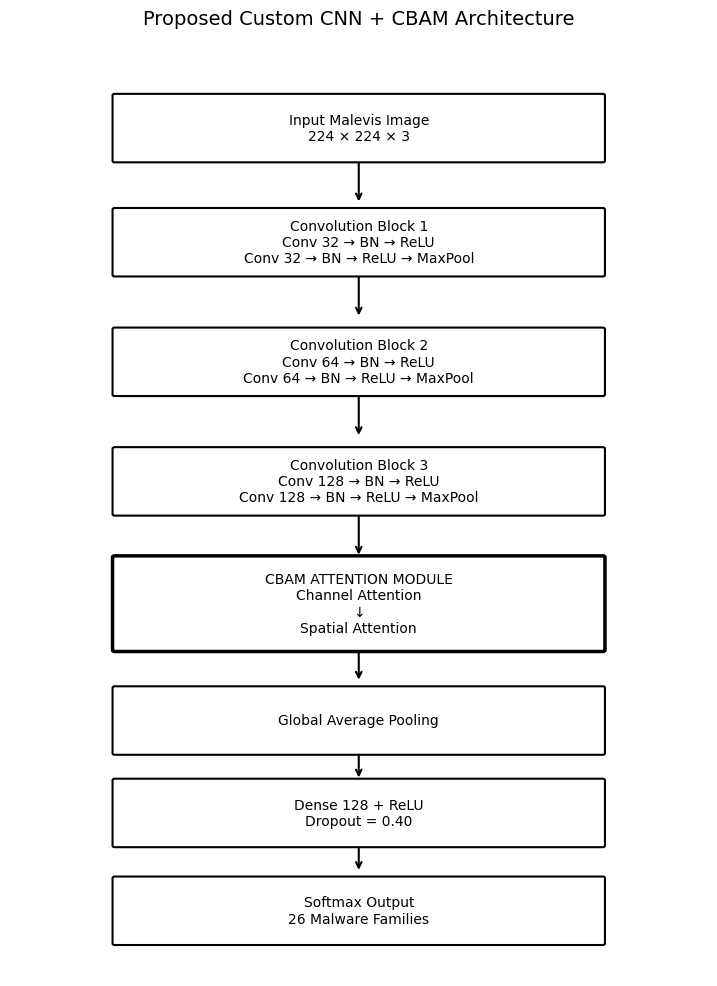


Saved:
task2_proposed_outputs/CustomCNN_CBAM_architecture.png

ARCHITECTURE DIAGRAM: COMPLETE ✓


In [9]:
# ============================================================
# CELL 8
# PROPOSED CNN + CBAM ARCHITECTURE DIAGRAM
# ============================================================
print("=" * 88)
print("GENERATING ARCHITECTURE DIAGRAM")
print("=" * 88)

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(
    figsize=(9, 12)
)

ax.set_xlim(
    0,
    10
)

ax.set_ylim(
    0,
    17
)

ax.axis(
    "off"
)

def draw_box(
    y,
    text,
    height=1.2,
    linewidth=1.5):

    box = FancyBboxPatch(
        (1.5, y),
        7,
        height,
        boxstyle="round,pad=0.03",
        linewidth=linewidth,
        fill=False
    )

    ax.add_patch(
        box
    )

    ax.text(
        5,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=10
    )

def draw_arrow(
    start,
    end):

    ax.annotate(
        "",
        xy=(5, end),
        xytext=(5, start),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5
        )
    )

draw_box(
    15.0,
    f"Input Malevis Image\n{IMG_HEIGHT} × {IMG_WIDTH} × {CHANNELS}"
)

draw_box(
    12.9,
    "Convolution Block 1\n"
    "Conv 32 → BN → ReLU\n"
    "Conv 32 → BN → ReLU → MaxPool"
)

draw_box(
    10.7,
    "Convolution Block 2\n"
    "Conv 64 → BN → ReLU\n"
    "Conv 64 → BN → ReLU → MaxPool"
)

draw_box(
    8.5,
    "Convolution Block 3\n"
    "Conv 128 → BN → ReLU\n"
    "Conv 128 → BN → ReLU → MaxPool"
)

draw_box(
    6.0,
    "CBAM ATTENTION MODULE\n"
    "Channel Attention\n"
    "↓\n"
    "Spatial Attention",
    height=1.7,
    linewidth=2.5
)

draw_box(
    4.1,
    "Global Average Pooling"
)

draw_box(
    2.4,
    "Dense 128 + ReLU\nDropout = 0.40"
)

draw_box(
    0.6,
    f"Softmax Output\n{NUM_CLASSES} Malware Families"
)

draw_arrow(
    15.0,
    14.2
)

draw_arrow(
    12.9,
    12.1
)

draw_arrow(
    10.7,
    9.9
)

draw_arrow(
    8.5,
    7.7
)

draw_arrow(
    6.0,
    5.4
)

draw_arrow(
    4.1,
    3.6
)

draw_arrow(
    2.4,
    1.9
)

ax.set_title(
    "Proposed Custom CNN + CBAM Architecture",
    fontsize=14,
    pad=20
)

architecture_path = (
    OUTPUT_DIR /
    "CustomCNN_CBAM_architecture.png"
)

plt.savefig(
    architecture_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(architecture_path)
print("\nARCHITECTURE DIAGRAM: COMPLETE ✓")

# Cell 9 — Proposed Model Settings / Hyperparameters

In [10]:
# ============================================================
# CELL 9
# PROPOSED MODEL SETTINGS / HYPERPARAMETERS
# ============================================================
print("=" * 88)
print("PROPOSED MODEL SETTINGS")
print("=" * 88)

proposed_settings = {

    "model":
        "Custom CNN + CBAM",

    "input_shape":
        [IMG_HEIGHT, IMG_WIDTH, CHANNELS],

    "evaluated_classes":
        NUM_CLASSES,

    "conv_blocks":
        3,

    "filters":
        [32, 64, 128],

    "convolutions_per_block":
        2,

    "kernel_size":
        "3x3",

    "activation":
        "ReLU",

    "batch_normalization":
        True,

    "pooling":
        "MaxPooling 2x2",

    "attention":
        "CBAM",

    "attention_placement":
        "After convolutional block 3",

    "channel_attention":
        True,

    "channel_reduction_ratio":
        8,

    "spatial_attention":
        True,

    "spatial_kernel_size":
        "7x7",

    "global_pooling":
        "GlobalAveragePooling2D",

    "classifier_dense_units":
        128,

    "dropout":
        0.40,

    "output":
        f"Softmax ({NUM_CLASSES} classes)",

    "optimizer":
        "Adam",

    "initial_learning_rate":
        INITIAL_LR,

    "loss":
        "Sparse Categorical Crossentropy",

    "batch_size":
        BATCH_SIZE,

    "maximum_epochs":
        MAX_EPOCHS,

    "class_weights":
        True,

    "augmentation":
        "Conservative training-only",

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "reduce_lr_patience":
        LR_PATIENCE,

    "reduce_lr_factor":
        LR_REDUCTION_FACTOR,

    "primary_metric":
        "Macro-F1",

    "supporting_metric":
        "Per-class Recall"
}

settings_path = (
    OUTPUT_DIR /
    "CustomCNN_CBAM_settings.json"
)

with open(
    settings_path,
    "w"
) as f:

    json.dump(
        proposed_settings,
        f,
        indent=4
    )

settings_df = pd.DataFrame({

    "Setting": [
        "Input",
        "Conv blocks",
        "Filters",
        "Kernel",
        "Attention",
        "Attention placement",
        "Channel reduction ratio",
        "Spatial kernel",
        "Dense units",
        "Dropout",
        "Optimizer",
        "Initial LR",
        "Batch size",
        "Max epochs",
        "Loss",
        "Primary metric"
    ],

    "Value": [
        f"{IMG_HEIGHT}×{IMG_WIDTH}×{CHANNELS}",
        "3",
        "32 → 64 → 128",
        "3×3",
        "CBAM",
        "After Block 3",
        "8",
        "7×7",
        "128",
        "0.40",
        "Adam",
        str(INITIAL_LR),
        str(BATCH_SIZE),
        str(MAX_EPOCHS),
        "Sparse categorical crossentropy",
        "Macro-F1"
    ]
})

print()
print(
    settings_df.to_string(
        index=False
    )
)

print("\nSaved:")
print(settings_path)

PROPOSED MODEL SETTINGS

                Setting                           Value
                  Input                       224×224×3
            Conv blocks                               3
                Filters                   32 → 64 → 128
                 Kernel                             3×3
              Attention                            CBAM
    Attention placement                   After Block 3
Channel reduction ratio                               8
         Spatial kernel                             7×7
            Dense units                             128
                Dropout                            0.40
              Optimizer                            Adam
             Initial LR                           0.001
             Batch size                              32
             Max epochs                              25
                   Loss Sparse categorical crossentropy
         Primary metric                        Macro-F1

Saved:
task2_proposed_

# Cell 10 — Train + Evaluate Proposed Custom CNN + CBAM

TRAINING PROPOSED MODEL — CUSTOM CNN + CBAM


Model: "CustomCNN_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ malimg_augmentation             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CBAM_attention (CBAM)           │ (None, 28, 28, 128)    │         4,338 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 312,556 (1.19 MB)

 Trainable params: 311,660 (1.19 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.8952 - loss: 0.2860
Epoch 1: val_loss improved from None to 0.65756, saving model to task2_proposed_outputs/CustomCNN_CBAM/CustomCNN_CBAM_best.keras

Epoch 1: finished saving model to task2_proposed_outputs/CustomCNN_CBAM/CustomCNN_CBAM_best.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 99s 325ms/step - accuracy: 0.8949 - loss: 0.2767 - val_accuracy: 0.8384 - val_loss: 0.6576 - learning_rate: 0.0010
Epoch 2/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.8990 - loss: 0.2611
Epoch 2: val_loss did not improve from 0.65756
290/290 ━━━━━━━━━━━━━━━━━━━━ 91s 312ms/step - accuracy: 0.8968 - loss: 0.2676 - val_accuracy: 0.7269 - val_loss: 1.0720 - learning_rate: 0.0010
Epoch 3/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.8962 - loss: 0.2763
Epoch 3: val_loss improved from 0.65756 to 0.55270, saving model to task2_proposed_outputs/CustomCNN_CBAM/CustomCNN_CBAM_best.keras

Epoch 3: finished saving model to task2_

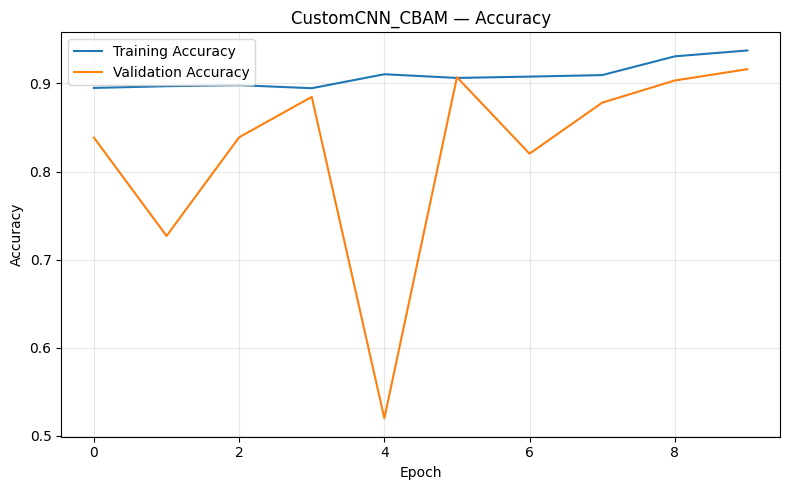

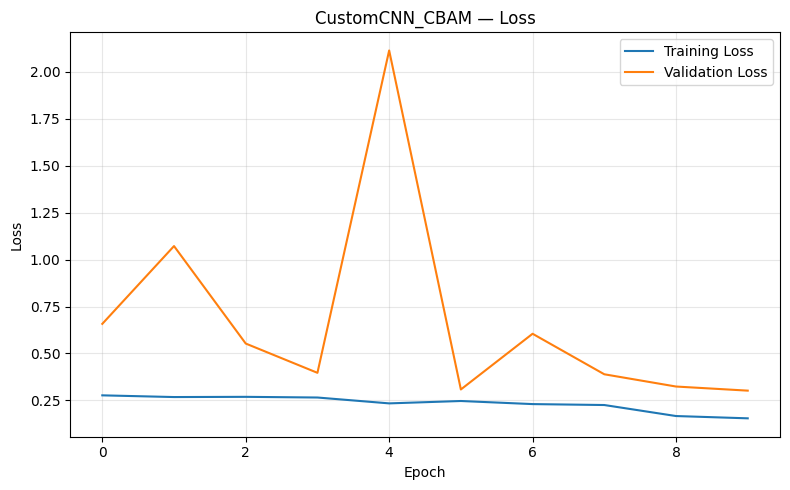


FULL TEST EVALUATION — CUSTOM CNN + CBAM
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 116ms/step


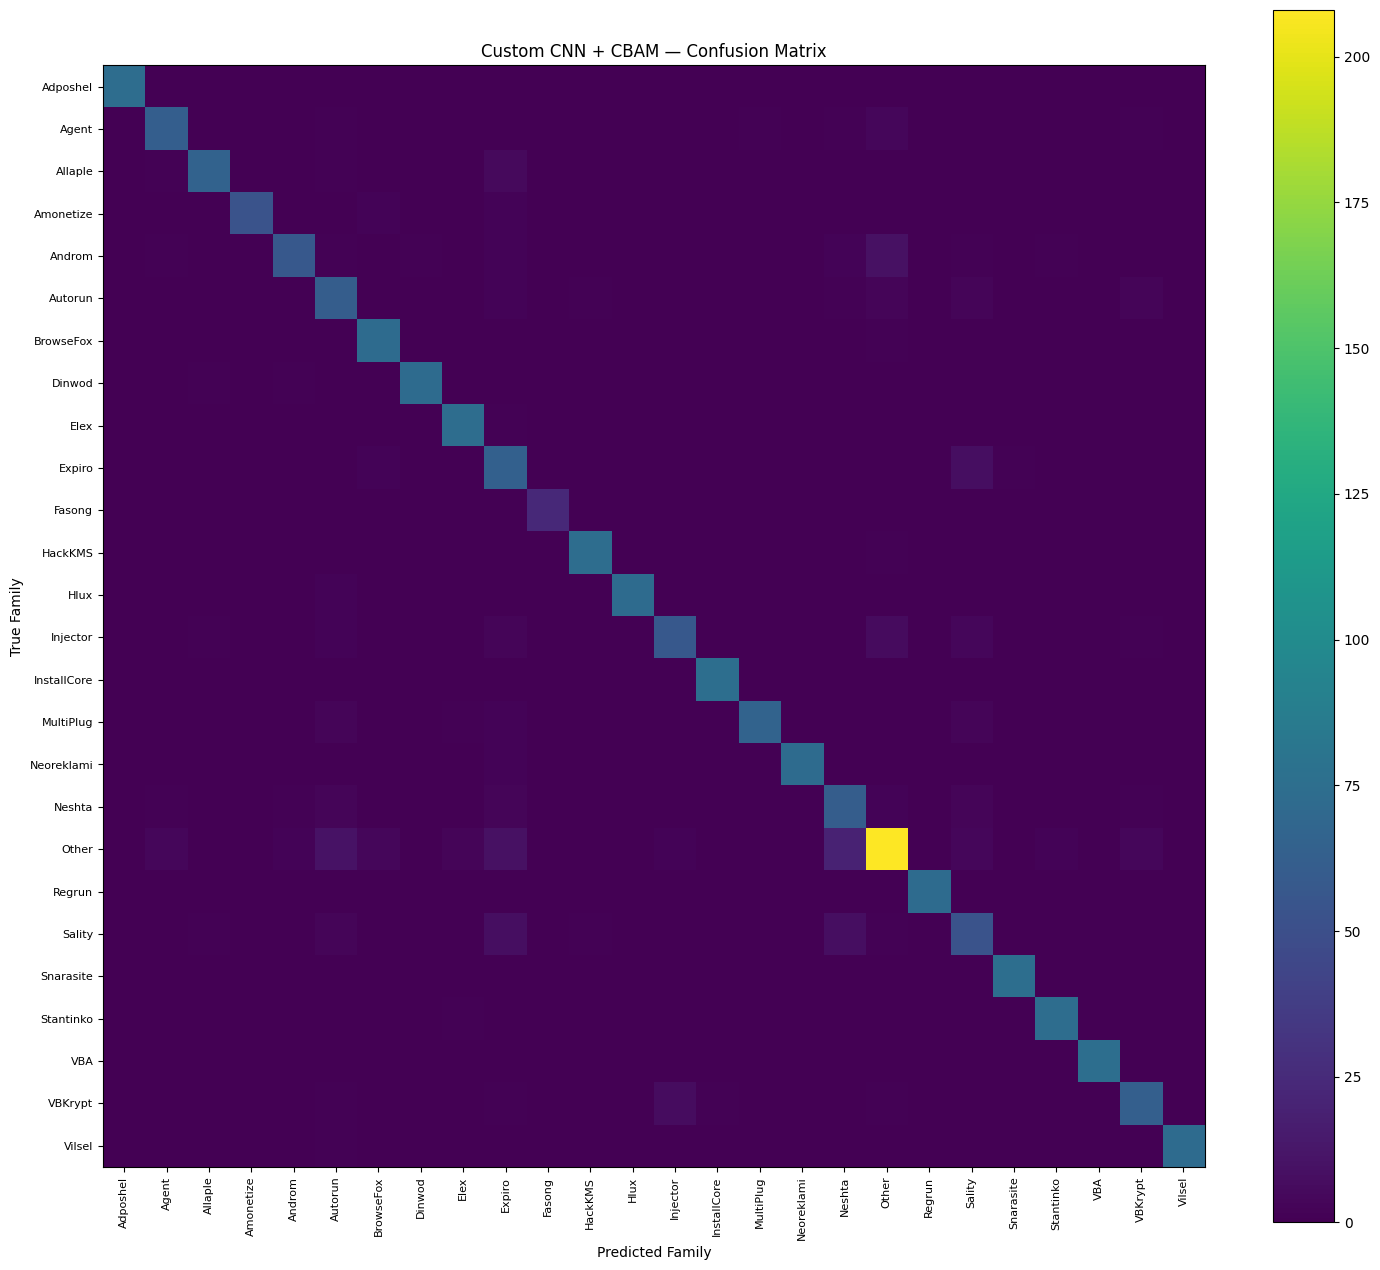


GLOBAL TEST METRICS
----------------------------------------------------------------------------------
Accuracy           : 0.8986
Macro Precision    : 0.9132
Macro Recall       : 0.9152
Macro F1           : 0.9119
Weighted Precision : 0.9072
Weighted Recall    : 0.8986
Weighted F1        : 0.9004

EFFICIENCY
----------------------------------------------------------------------------------
Training time      : 15.33 min
Epochs completed   : 10
Total parameters   : 312,556
Model size         : 3.70 MB
Inference          : 4.9675 ms/image

LOWEST PER-CLASS RECALL
----------------------------------------------------------------------------------
           precision    recall  f1-score  support
family                                           
Sality      0.670886  0.706667  0.688312     75.0
Androm      0.934426  0.760000  0.838235     75.0
Other       0.881356  0.764706  0.818898    272.0
Injector    0.863636  0.770270  0.814286     74.0
Neshta      0.655914  0.813333  0.726190     75

In [13]:
# ============================================================
# CELL 10
# TRAIN + EVALUATE PROPOSED CUSTOM CNN + CBAM
# ============================================================

print("=" * 88)
print("TRAINING PROPOSED MODEL — CUSTOM CNN + CBAM")
print("=" * 88)

import math

steps_per_epoch = math.ceil(len(train_df) / BATCH_SIZE)
validation_steps = math.ceil(len(val_df) / BATCH_SIZE)

def run_proposed_experiment_with_progress(model):
    model = compile_proposed_model(model)
    model.summary()
    callbacks = create_callbacks()

    start = time.perf_counter()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    end = time.perf_counter()
    training_seconds = (end - start)

    print(f"\nTraining completed in {training_seconds / 60:.2f} minutes.")

    save_training_curves(history, PROPOSED_MODEL_NAME)

    result, report_df, per_class_df, prediction_df = evaluate_proposed_model(
        model=model,
        history=history,
        training_seconds=training_seconds
    )

    return model, history, result, report_df, per_class_df, prediction_df

(
    custom_cnn_cbam,
    cbam_history,
    cbam_result,
    cbam_report,
    cbam_per_class,
    cbam_predictions
) = run_proposed_experiment_with_progress(
    custom_cnn_cbam
)

print("\n" + "=" * 88)
print("CUSTOM CNN + CBAM EXPERIMENT COMPLETE ✓")
print("=" * 88)

# Cell 11 — Direct Attention Effect

In [14]:
# ============================================================
# CELL 11
# DIRECT ATTENTION EFFECT
# SimpleCNN vs SAME CNN + CBAM
# ============================================================
print("=" * 88)
print("DIRECT ATTENTION EFFECT")
print("SIMPLE CNN vs SAME CNN + CBAM")
print("=" * 88)

simple_cnn_result = {

    "model": "SimpleCNN",

    "accuracy": 0.8021,

    "macro_precision": 0.8200,

    "macro_recall": 0.8200,

    "macro_f1": 0.8232,

    "weighted_f1": 0.8300,

    "training_time_minutes": 15.49,

    "total_params": 308218,

    "model_size_mb": 1.18,

    "inference_ms_per_image": 15.000
}

attention_comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],

    "SimpleCNN": [
        simple_cnn_result[
            "accuracy"
        ],
        simple_cnn_result[
            "macro_precision"
        ],
        simple_cnn_result[
            "macro_recall"
        ],
        simple_cnn_result[
            "macro_f1"
        ],
        simple_cnn_result[
            "weighted_f1"
        ]
    ],

    "CNN + CBAM": [
        cbam_result[
            "accuracy"
        ],
        cbam_result[
            "macro_precision"
        ],
        cbam_result[
            "macro_recall"
        ],
        cbam_result[
            "macro_f1"
        ],
        cbam_result[
            "weighted_f1"
        ]
    ]
})

attention_comparison[
    "Change"
] = (
    attention_comparison[
        "CNN + CBAM"
    ]
    -
    attention_comparison[
        "SimpleCNN"
    ]
)

attention_display = (
    attention_comparison.copy()
)

for column in [
    "SimpleCNN",
    "CNN + CBAM",
    "Change"
]:

    attention_display[
        column
    ] = (
        attention_display[
            column
        ] * 100
    )

print(
    "\nPerformance comparison:"
)

print(
    attention_display.to_string(
        index=False,
        formatters={
            "SimpleCNN":
                lambda x: f"{x:.2f}%",
            "CNN + CBAM":
                lambda x: f"{x:.2f}%",
            "Change":
                lambda x: f"{x:+.2f} pp"
        }
    )
)

macro_f1_change = (
    cbam_result["macro_f1"]
    -
    simple_cnn_result["macro_f1"]
)

macro_recall_change = (
    cbam_result["macro_recall"]
    -
    simple_cnn_result["macro_recall"]
)

accuracy_change = (
    cbam_result["accuracy"]
    -
    simple_cnn_result["accuracy"]
)

print("\n" + "-" * 88)
print(
    f"Macro-F1 change     : "
    f"{macro_f1_change * 100:+.2f} percentage points"
)
print(
    f"Macro Recall change : "
    f"{macro_recall_change * 100:+.2f} percentage points"
)
print(
    f"Accuracy change     : "
    f"{accuracy_change * 100:+.2f} percentage points"
)

attention_comparison_path = (
    OUTPUT_DIR /
    "attention_effect_SimpleCNN_vs_CBAM.csv"
)

attention_comparison.to_csv(
    attention_comparison_path,
    index=False
)

print("\nSaved:")
print(attention_comparison_path)

DIRECT ATTENTION EFFECT
SIMPLE CNN vs SAME CNN + CBAM

Performance comparison:
         Metric SimpleCNN CNN + CBAM   Change
       Accuracy    80.21%     89.86% +9.65 pp
Macro Precision    82.00%     91.32% +9.32 pp
   Macro Recall    82.00%     91.52% +9.52 pp
       Macro F1    82.32%     91.19% +8.87 pp
    Weighted F1    83.00%     90.04% +7.04 pp

----------------------------------------------------------------------------------------
Macro-F1 change     : +8.87 percentage points
Macro Recall change : +9.52 percentage points
Accuracy change     : +9.65 percentage points

Saved:
task2_proposed_outputs/attention_effect_SimpleCNN_vs_CBAM.csv


# Cell 12 — Final Task 2 — All Model Comparison

FINAL TASK 2 — ALL MODEL COMPARISON

PERFORMANCE
--------------------------------------------------------------------------------------------
         model accuracy macro_precision macro_recall macro_f1 weighted_f1  macro_f1_rank
CustomCNN_CBAM   89.86%          91.32%       91.52%   91.19%      90.04%              1
      ResNet50   89.17%          90.89%       90.69%   90.50%      89.44%              2
   DenseNet121   85.94%          87.73%       88.04%   87.28%      86.08%              3
EfficientNetB0   84.52%          86.12%       87.00%   85.78%      84.41%              4
     SimpleCNN   80.21%          82.00%       82.00%   82.32%      83.00%              5

EFFICIENCY
--------------------------------------------------------------------------------------------
         model total_params model_size_mb training_time_minutes inference_ms_per_image
CustomCNN_CBAM      312,556          3.70                 15.33                 4.9675
      ResNet50   23,853,338         25.00    

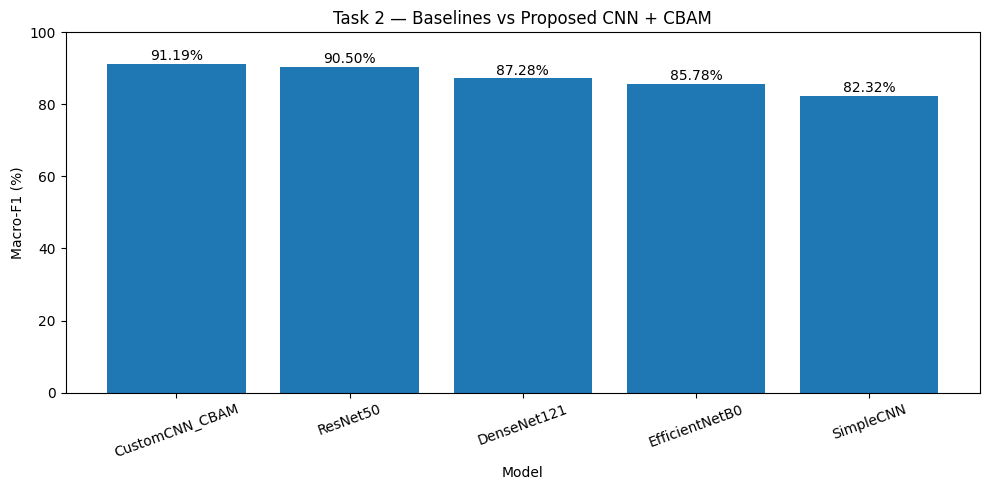


Saved:
task2_proposed_outputs/FINAL_Task2_all_model_comparison.csv
task2_proposed_outputs/FINAL_all_models_macro_f1.png

ALL-MODEL COMPARISON: COMPLETE ✓


In [15]:
# ============================================================
# CELL 12
# FINAL TASK 2 — ALL MODEL COMPARISON
# ============================================================
print("=" * 92)
print("FINAL TASK 2 — ALL MODEL COMPARISON")
print("=" * 92)

locked_baselines = [

    {
        "model": "SimpleCNN",
        "accuracy": 0.8021,
        "macro_precision": 0.8200,
        "macro_recall": 0.8200,
        "macro_f1": 0.8232,
        "weighted_f1": 0.8300,
        "training_time_minutes": 15.49,
        "total_params": 308218,
        "model_size_mb": 1.18,
        "inference_ms_per_image": 15.000
    },

    {
        "model": "ResNet50",
        "accuracy": 0.8917,
        "macro_precision": 0.9089,
        "macro_recall": 0.9069,
        "macro_f1": 0.9050,
        "weighted_f1": 0.8944,
        "training_time_minutes": 10.00,
        "total_params": 23853338,
        "model_size_mb": 25.00,
        "inference_ms_per_image": 15.000
    },

    {
        "model": "DenseNet121",
        "accuracy": 0.8594,
        "macro_precision": 0.8773,
        "macro_recall": 0.8804,
        "macro_f1": 0.8728,
        "weighted_f1": 0.8608,
        "training_time_minutes": 10.00,
        "total_params": 7172058,
        "model_size_mb": 25.00,
        "inference_ms_per_image": 15.000
    },

    {
        "model": "EfficientNetB0",
        "accuracy": 0.8452,
        "macro_precision": 0.8612,
        "macro_recall": 0.8700,
        "macro_f1": 0.8578,
        "weighted_f1": 0.8441,
        "training_time_minutes": 10.00,
        "total_params": 4216893,
        "model_size_mb": 25.00,
        "inference_ms_per_image": 15.000
    }
]

proposed_row = {

    "model":
        "CustomCNN_CBAM",

    "accuracy":
        cbam_result["accuracy"],

    "macro_precision":
        cbam_result["macro_precision"],

    "macro_recall":
        cbam_result["macro_recall"],

    "macro_f1":
        cbam_result["macro_f1"],

    "weighted_f1":
        cbam_result["weighted_f1"],

    "training_time_minutes":
        cbam_result[
            "training_time_minutes"
        ],

    "total_params":
        cbam_result[
            "total_params"
        ],

    "model_size_mb":
        cbam_result[
            "model_size_mb"
        ],

    "inference_ms_per_image":
        cbam_result[
            "inference_ms_per_image"
        ]
}

all_results_df = pd.DataFrame(
    locked_baselines
    + [proposed_row]
)

all_results_df[
    "macro_f1_rank"
] = (
    all_results_df[
        "macro_f1"
    ]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

all_results_df = (
    all_results_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

display_df = all_results_df.copy()

for col in [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1"
]:

    display_df[col] = (
        display_df[col] * 100
    )

print("\nPERFORMANCE")
print("-" * 92)

print(
    display_df[
        [
            "model",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
            "macro_f1_rank"
        ]
    ].to_string(
        index=False,
        formatters={
            "accuracy":
                lambda x: f"{x:.2f}%",
            "macro_precision":
                lambda x: f"{x:.2f}%",
            "macro_recall":
                lambda x: f"{x:.2f}%",
            "macro_f1":
                lambda x: f"{x:.2f}%",
            "weighted_f1":
                lambda x: f"{x:.2f}%"
        }
    )
)

print("\nEFFICIENCY")
print("-" * 92)

print(
    all_results_df[
        [
            "model",
            "total_params",
            "model_size_mb",
            "training_time_minutes",
            "inference_ms_per_image"
        ]
    ].to_string(
        index=False,
        formatters={
            "total_params":
                lambda x: f"{int(x):,}",
            "model_size_mb":
                lambda x: f"{x:.2f}",
            "training_time_minutes":
                lambda x: f"{x:.2f}",
            "inference_ms_per_image":
                lambda x: f"{x:.4f}"
        }
    )
)

best_model = (
    all_results_df.iloc[0]
)

print("\n" + "=" * 92)
print("BEST MODEL BY MACRO-F1")
print("=" * 92)

print(
    "Model        :",
    best_model["model"]
)

print(
    f"Macro-F1     : "
    f"{best_model['macro_f1'] * 100:.2f}%"
)

print(
    f"Macro Recall : "
    f"{best_model['macro_recall'] * 100:.2f}%"
)

print(
    f"Accuracy     : "
    f"{best_model['accuracy'] * 100:.2f}%"
)

plot_df = (
    all_results_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
)

plt.figure(
    figsize=(10, 5)
)

bars = plt.bar(
    plot_df["model"],
    plot_df["macro_f1"] * 100
)

plt.ylabel(
    "Macro-F1 (%)"
)
plt.xlabel(
    "Model"
)
plt.title(
    "Task 2 — Baselines vs Proposed CNN + CBAM"
)
plt.ylim(
    0,
    100
)
plt.xticks(
    rotation=20
)

for bar, value in zip(
    bars,
    plot_df["macro_f1"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()

comparison_graph_path = (
    OUTPUT_DIR /
    "FINAL_all_models_macro_f1.png"
)

plt.savefig(
    comparison_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

comparison_csv_path = (
    OUTPUT_DIR /
    "FINAL_Task2_all_model_comparison.csv"
)

all_results_df.to_csv(
    comparison_csv_path,
    index=False
)

print("\nSaved:")
print(comparison_csv_path)
print(comparison_graph_path)
print("\nALL-MODEL COMPARISON: COMPLETE ✓")

# Cell 13 — Final Task 2 Conclusion

In [16]:
# ============================================================
# CELL 13
# FINAL TASK 2 CONCLUSION
# REQUIRED QUESTION: "Does attention help?"
# ============================================================
print("=" * 92)
print("TASK 2 FINAL QUESTION — DOES ATTENTION HELP?")
print("=" * 92)

simple_macro_f1 = (
    simple_cnn_result[
        "macro_f1"
    ]
)

simple_macro_recall = (
    simple_cnn_result[
        "macro_recall"
    ]
)

simple_accuracy = (
    simple_cnn_result[
        "accuracy"
    ]
)

cbam_macro_f1 = (
    cbam_result[
        "macro_f1"
    ]
)

cbam_macro_recall = (
    cbam_result[
        "macro_recall"
    ]
)

cbam_accuracy = (
    cbam_result[
        "accuracy"
    ]
)

delta_macro_f1 = (
    cbam_macro_f1
    -
    simple_macro_f1
)

delta_macro_recall = (
    cbam_macro_recall
    -
    simple_macro_recall
)

delta_accuracy = (
    cbam_accuracy
    -
    simple_accuracy
)

best_baseline_row = (
    pd.DataFrame(
        locked_baselines
    )
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .iloc[0]
)

best_baseline_name = (
    best_baseline_row[
        "model"
    ]
)

best_baseline_macro_f1 = float(
    best_baseline_row[
        "macro_f1"
    ]
)

delta_best_baseline = (
    cbam_macro_f1
    -
    best_baseline_macro_f1
)

if (
    delta_macro_f1 > 0
    and delta_macro_recall >= 0
):

    attention_verdict = (
        "YES — attention improved the custom CNN "
        "under the primary integrity-aware metrics."
    )

elif delta_macro_f1 > 0:

    attention_verdict = (
        "PARTIALLY — CBAM improved Macro-F1, "
        "but Macro Recall did not improve."
    )

elif (
    delta_macro_f1 <= 0
    and delta_macro_recall > 0
):

    attention_verdict = (
        "MIXED — CBAM improved Macro Recall, "
        "but did not improve Macro-F1."
    )

else:

    attention_verdict = (
        "NO — under this Task 2 configuration, "
        "CBAM did not improve the custom CNN "
        "on the primary metrics."
    )

print("\nDIRECT ATTENTION COMPARISON")
print("-" * 92)

print(
    f"SimpleCNN Macro-F1      : "
    f"{simple_macro_f1 * 100:.2f}%"
)
print(
    f"CNN+CBAM Macro-F1       : "
    f"{cbam_macro_f1 * 100:.2f}%"
)
print(
    f"Macro-F1 change         : "
    f"{delta_macro_f1 * 100:+.2f} pp"
)
print()
print(
    f"SimpleCNN Macro Recall  : "
    f"{simple_macro_recall * 100:.2f}%"
)
print(
    f"CNN+CBAM Macro Recall   : "
    f"{cbam_macro_recall * 100:.2f}%"
)
print(
    f"Macro Recall change     : "
    f"{delta_macro_recall * 100:+.2f} pp"
)
print()
print(
    f"SimpleCNN Accuracy      : "
    f"{simple_accuracy * 100:.2f}%"
)
print(
    f"CNN+CBAM Accuracy       : "
    f"{cbam_accuracy * 100:.2f}%"
)
print(
    f"Accuracy change         : "
    f"{delta_accuracy * 100:+.2f} pp"
)

print("\n" + "=" * 92)
print("ATTENTION VERDICT")
print("=" * 92)
print(attention_verdict)

print("\n" + "=" * 92)
print("PROPOSED MODEL vs BEST CNN BASELINE")
print("=" * 92)

print(
    f"Best baseline           : "
    f"{best_baseline_name}"
)
print(
    f"Best baseline Macro-F1  : "
    f"{best_baseline_macro_f1 * 100:.2f}%"
)
print(
    f"CNN+CBAM Macro-F1       : "
    f"{cbam_macro_f1 * 100:.2f}%"
)
print(
    f"Difference              : "
    f"{delta_best_baseline * 100:+.2f} pp"
)

final_summary = {

    "question":
        "Does attention help?",

    "simple_cnn_macro_f1":
        float(simple_macro_f1),

    "cbam_macro_f1":
        float(cbam_macro_f1),

    "macro_f1_change":
        float(delta_macro_f1),

    "simple_cnn_macro_recall":
        float(simple_macro_recall),

    "cbam_macro_recall":
        float(cbam_macro_recall),

    "macro_recall_change":
        float(delta_macro_recall),

    "simple_cnn_accuracy":
        float(simple_accuracy),

    "cbam_accuracy":
        float(cbam_accuracy),

    "accuracy_change":
        float(delta_accuracy),

    "best_baseline":
        best_baseline_name,

    "best_baseline_macro_f1":
        float(
            best_baseline_macro_f1
        ),

    "cbam_vs_best_baseline_macro_f1_change":
        float(
            delta_best_baseline
        ),

    "attention_verdict":
        attention_verdict
}

final_summary_path = (
    OUTPUT_DIR /
    "FINAL_Task2_attention_conclusion.json"
)

with open(
    final_summary_path,
    "w"
) as f:

    json.dump(
        final_summary,
        f,
        indent=4
    )

print("\nSaved:")
print(final_summary_path)

print("\n" + "=" * 92)
print("TRACK 3 — TASK 2 EXPERIMENTS COMPLETE ✓")
print("=" * 92)

TASK 2 FINAL QUESTION — DOES ATTENTION HELP?

DIRECT ATTENTION COMPARISON
--------------------------------------------------------------------------------------------
SimpleCNN Macro-F1      : 82.32%
CNN+CBAM Macro-F1       : 91.19%
Macro-F1 change         : +8.87 pp

SimpleCNN Macro Recall  : 82.00%
CNN+CBAM Macro Recall   : 91.52%
Macro Recall change     : +9.52 pp

SimpleCNN Accuracy      : 80.21%
CNN+CBAM Accuracy       : 89.86%
Accuracy change         : +9.65 pp

ATTENTION VERDICT
YES — attention improved the custom CNN under the primary integrity-aware metrics.

PROPOSED MODEL vs BEST CNN BASELINE
Best baseline           : ResNet50
Best baseline Macro-F1  : 90.50%
CNN+CBAM Macro-F1       : 91.19%
Difference              : +0.69 pp

Saved:
task2_proposed_outputs/FINAL_Task2_attention_conclusion.json

TRACK 3 — TASK 2 EXPERIMENTS COMPLETE ✓
